<a href="https://colab.research.google.com/github/klissiadev/PP2.1_Perceptron/blob/main/PP21_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

from perceptron import (
    ArquivosDados, AvaliadorBinario, CarregadorDados, ConfiguracaoPerceptron,
    ExperimentoConfiguracoes, FormatadorAvaliacao, FormatadorExperimento,
    Grupo, Integrante, Perceptron, VisualizadorExperimento, VisualizadorPerceptron,
)

In [2]:
grupo = Grupo(integrantes=(
    Integrante(nome="Ana Klissia Furtado Martins", matricula="2415310025"),
    Integrante(nome="Nathalia Nóbrega Silva", matricula="2415310021"),
))

identificador = grupo.identificador
print(f"Identificador: {identificador}")

Identificador: 2


In [3]:
arquivos = ArquivosDados(identificador=identificador)

for caminho, existe in arquivos.verificar_existencia().items():
    situacao = "encontrado" if existe else "não encontrado"
    print(f"Arquivo {situacao}: {caminho.name}")

Arquivo encontrado: dataAll20262.txt
Arquivo encontrado: data220262.txt
Arquivo encontrado: dataHoldout20262.txt


# Parte I

In [4]:
# Cores das classes para visualização
COR_CLASSE_0 = "red"
COR_CLASSE_1 = "blue"

# Escala máxima dos atrivutos, usada para normalizar as Partes II e III.
# JUSTIFICATIVA: o X2 leva +40 minutos para rodar sem normalização.
ESCALA_NORMALIZACAO = 1000

In [5]:
# Carregamento dos dados da Parte I
dados_parte_1 = CarregadorDados.carregar(arquivos.parte_1)

print("Formato dos dados:", dados_parte_1.X.shape)
print("Quantidade de exemplos:", len(dados_parte_1))
print("Classes encontradas:", dados_parte_1.classes)
print("Primeiros 3 exemplos (X):")
print(dados_parte_1.X[:3])

Formato dos dados: (1000, 2)
Quantidade de exemplos: 1000
Classes encontradas: [0 1]
Primeiros 3 exemplos (X):
[[ 547.91209711 -122.2431205 ]
 [ 717.19583982  394.73605812]
 [-811.64530422  951.24470327]]


In [6]:
# Instanciação e treinamento do Perceptron da Parte I
configuracao_parte_1 = ConfiguracaoPerceptron(
    taxa_aprendizado=0.1,
    intervalo_pesos=(-0.5, 0.5),
    limiar=0.0,
    max_epocas=100_000,
    embaralhar=False,
)

modelo_parte_1 = Perceptron(configuracao_parte_1)
modelo_parte_1.fit(dados_parte_1.X, dados_parte_1.y)

historico_parte_1 = modelo_parte_1.historico
print("Pesos iniciais:", historico_parte_1.pesos_iniciais)
print("Pesos finais:", modelo_parte_1.pesos)
print("Total de ajustes:", historico_parte_1.total_ajustes)
print("Épocas executadas:", historico_parte_1.epocas_executadas)
print("Convergiu:", historico_parte_1.convergiu)

if not historico_parte_1.convergiu:
    print("O algoritmo não convergiu dentro do limite.")

Pesos iniciais: [-0.31081027 -0.11214041 -0.39679565]
Pesos finais: [ 8.61573422e+01 -4.26071016e+02 -2.96795649e-01]
Total de ajustes: 65
Épocas executadas: 4
Convergiu: True


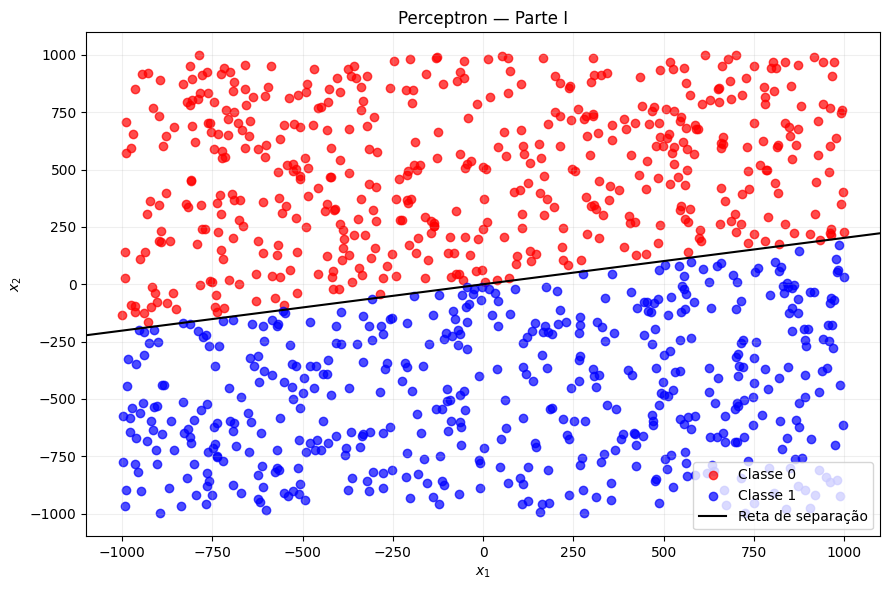

In [7]:
# Exibição do gráfico da Parte I
visualizador = VisualizadorPerceptron(cor_classe_0=COR_CLASSE_0, cor_classe_1=COR_CLASSE_1)

if modelo_parte_1.historico.convergiu:
    visualizador.plotar_fronteira(dados_parte_1, modelo_parte_1.pesos, titulo="Perceptron — Parte I")

# Parte II

In [8]:
# Carregamento e normalização dos dados da Parte II
dados_parte_2 = CarregadorDados.carregar(arquivos.parte_2).normalizar(ESCALA_NORMALIZACAO)

print("Arquivo:", arquivos.parte_2.name)

Arquivo: data220262.txt


In [9]:
# Execução do experimento empírico
experimento = ExperimentoConfiguracoes(
    taxas_aprendizado=[0.4, 0.1, 0.01],
    intervalos=[(-100, 100), (-0.5, 0.5)],
    configuracao_base=ConfiguracaoPerceptron(max_epocas=100_000, embaralhar=False),
    num_repeticoes=10,
    seed=13,
)

resultados = experimento.executar(dados_parte_2)

In [10]:
# Tabela formatada com os resultados das execuções
print(FormatadorExperimento.tabela(resultados))

+---------------------+--------------------+--------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes    | Min Épocas | Max Épocas |
+---------------------+--------------------+--------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    |  801.40 ± 930.77   |     4      |    930     |
|       η = 0.4       |    (-0.5, +0.5)    |  887.90 ± 353.26   |     19     |    143     |
|       η = 0.1       |    (-100, +100)    |  1268.70 ± 697.64  |     10     |    144     |
|       η = 0.1       |    (-0.5, +0.5)    |  730.20 ± 255.88   |     16     |    101     |
|       η = 0.01      |    (-100, +100)    | 11850.00 ± 3321.45 |     35     |    242     |
|       η = 0.01      |    (-0.5, +0.5)    |  669.60 ± 415.33   |     3      |    196     |
+---------------------+--------------------+--------------------+------------+------------+


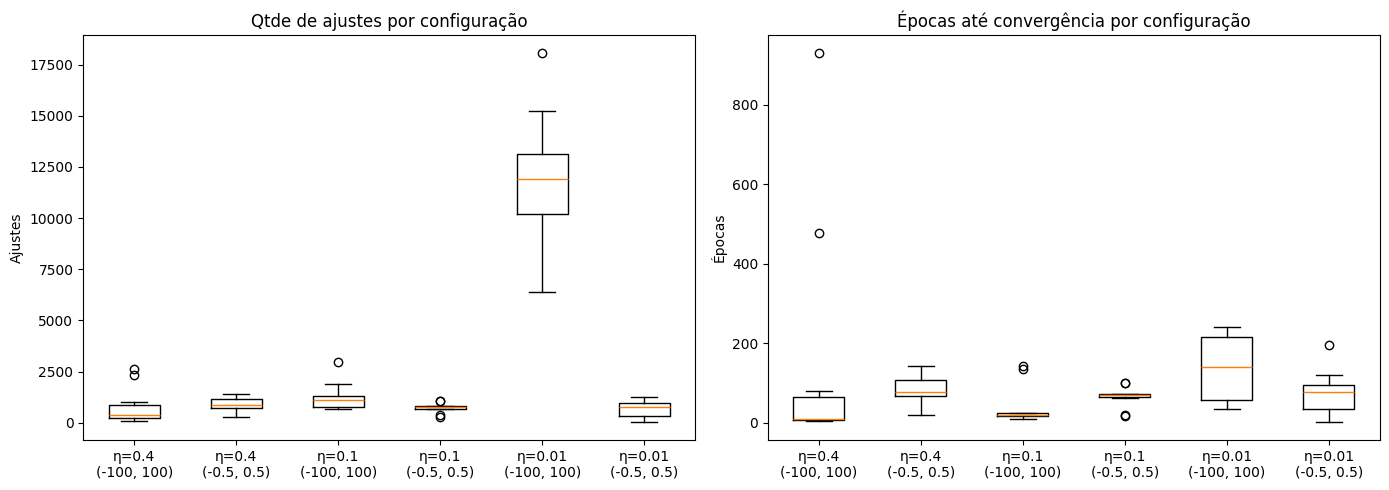

In [11]:
# Boxplots dos experimentos por configuração de hiperparâmetros
VisualizadorExperimento.plotar_boxplots(resultados)

##  é possível afirmar acerca da existência de uma configuração melhor ou pior que as demais ou se elas são equivalentes?

Sim, existe uma configuração pior. A configuração η = 0.01      |    (-100, +100)    | 11850.00 ± 3321.45 |     35     |    242 apresentou piores resultados com esse intervalo do que as outras configurações. O boxplot pode demonstrar o tamanho da discrepância com relação às demais. A configuração também apresentou o maior valor mínimo de épocas (35).

Sobre a existência de uma configuração superior, não é possível afirmar, já que as demais configurações apresentaram médias entre 669,6 e 1.268,7 ajustes, com desvios padrão de 255,9 a 930,8 da mesma ordem das diferenças entre as médias.



# Parte III

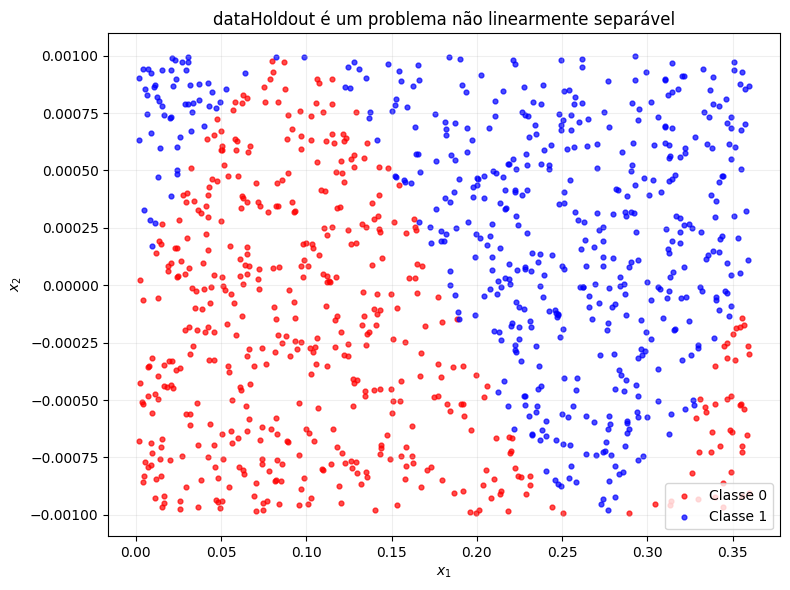

In [12]:
# Gráfico inicial evidenciando que o problema dataHoldout não é linearmente separável
dados_holdout = CarregadorDados.carregar(arquivos.parte_3).normalizar(ESCALA_NORMALIZACAO)

visualizador.plotar_dispersao(
    dados_holdout,
    titulo="dataHoldout é um problema não linearmente separável",
)

In [13]:
# Divisão dos exemplos em duas partições aleatórias: 70% treino e 30% teste.
# O mesmo gerador (semente = identificador) é reutilizado no treinamento da célula seguinte.
rng_holdout = np.random.RandomState(identificador)

treino, teste = dados_holdout.dividir(proporcao_treino=0.7, rng=rng_holdout)

print(f"Treino: {len(treino)} exemplos | classes: {treino.contagem_por_classe}")
print(f"Teste : {len(teste)} exemplos | classes: {teste.contagem_por_classe}")

Treino: 700 exemplos | classes: [349 351]
Teste : 300 exemplos | classes: [143 157]


In [14]:
# Treinamento do Perceptron no conjunto Holdout (100 épocas fixas com embaralhamento)
configuracao_holdout = ConfiguracaoPerceptron(
    taxa_aprendizado=0.1,
    intervalo_pesos=(-0.5, 0.5),
    max_epocas=100,
    embaralhar=True,
)

modelo_holdout = Perceptron(configuracao_holdout, rng=rng_holdout)
modelo_holdout.fit(treino.X, treino.y)

pesos_holdout = modelo_holdout.pesos
historico_holdout = modelo_holdout.historico

print("Pesos iniciais:", historico_holdout.pesos_iniciais)
print("Pesos finais  :", pesos_holdout)
print("Total de ajustes:", historico_holdout.total_ajustes)

Pesos iniciais: [ 0.08785124 -0.07246546  0.03321822]
Pesos finais  : [ 0.2833727   0.72195631 -0.06678178]
Total de ajustes: 21157


In [15]:
avaliador = AvaliadorBinario(modelo_holdout)

# Matriz de confusão do conjunto de teste
print("Matriz de confusão (conjunto de teste, classe positiva = 1):")
print(FormatadorAvaliacao.matriz_confusao(avaliador.matriz_confusao(teste)))

# Métricas comparativas nos conjuntos de Treino, Teste e Total
metricas_por_conjunto = {
    "Treino": avaliador.metricas(treino),
    "Teste": avaliador.metricas(teste),
    "Todos os dados": avaliador.metricas(dados_holdout),
}
print(FormatadorAvaliacao.metricas(metricas_por_conjunto))

Matriz de confusão (conjunto de teste, classe positiva = 1):
+-----------------+------------+------------+
| Real \ Previsto | Previsto 0 | Previsto 1 |
+-----------------+------------+------------+
|      Real 0     |  125 (VN)  |  18 (FP)   |
|      Real 1     |  65 (FN)   |  92 (VP)   |
+-----------------+------------+------------+
+----------------+----------+----------+-----------+---------+
|    Conjunto    | Acurácia | Precisão | Revocação | F-Score |
+----------------+----------+----------+-----------+---------+
|     Treino     |  0.7471  |  0.8816  |   0.5726  |  0.6943 |
|     Teste      |  0.7233  |  0.8364  |   0.5860  |  0.6891 |
| Todos os dados |  0.7400  |  0.8669  |   0.5768  |  0.6927 |
+----------------+----------+----------+-----------+---------+


# Acerca da qualidade da solução perante o conjunto de testes

No conjunto de teste, o neurônio obteve acurácia de 72,33%
(217 acertos em 300 exemplos). A
reta aprendeu alguma estrutura dos dados. Ainda assim, mais de um
quarto dos exemplos de teste (83 de 300) foi classificado incorretamente.Além disso, s métricas de treino e teste são próximas (acurácia de 74,71% e 72,33%), o que indica ausência de sobreajuste relevante.

A solução generaliza de forma consistente, porém perde parte importante da classe 1.

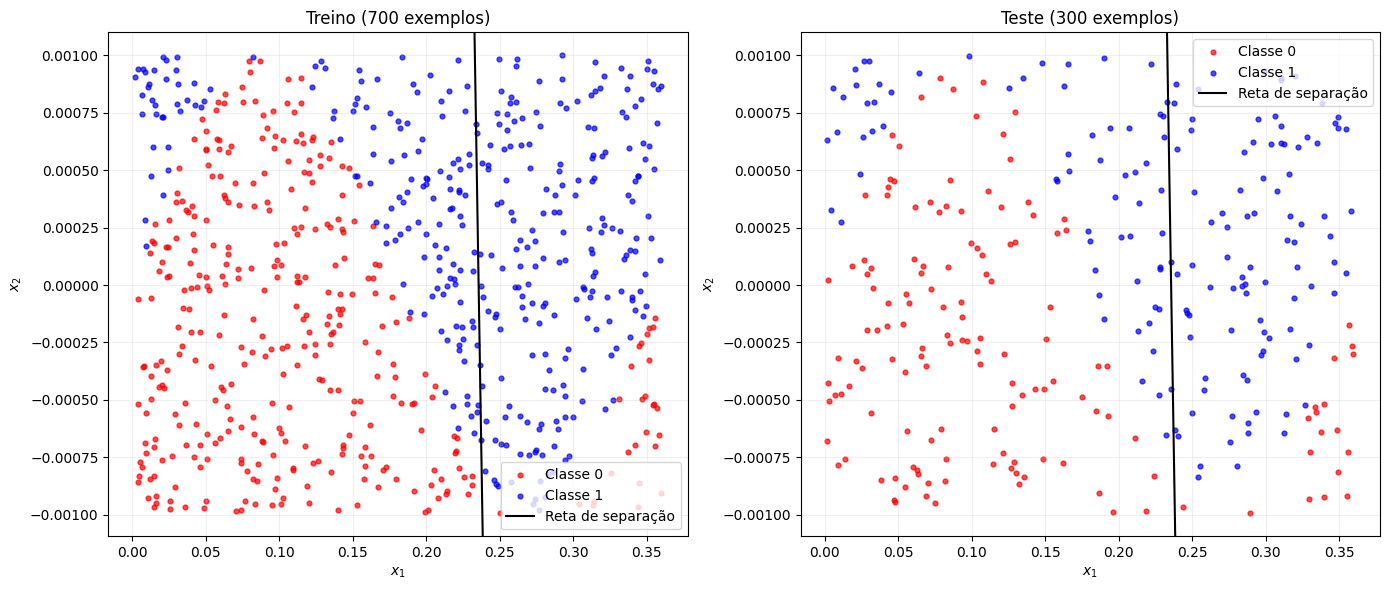

In [16]:
# Renderização lado a lado da reta de separação nos conjuntos de Treino e Teste
visualizador.plotar_comparacao_treino_teste(
    treino,
    teste,
    pesos=pesos_holdout,
    referencia=dados_holdout,
)